# Exploratory Data Analysis

**Methodology step:** Step 3 (see `docs/methodology.md`)

**Purpose:** Explore the distribution of `claim` and its relationship with each variable; generate hypotheses for formal testing.

**Status:** Not started.

In [1]:
import os
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

if Path.cwd().name == "notebooks":
    os.chdir("..")

# Load the cleaned table into pandas, then close the connection
# so the DuckDB shell isn't locked out
con = duckdb.connect("data/processed/insurance.duckdb", read_only=True)
df = con.sql("SELECT * FROM insurance_cleaned").df()
con.close()

sns.set_theme(style="whitegrid")
df.shape


(1332, 10)

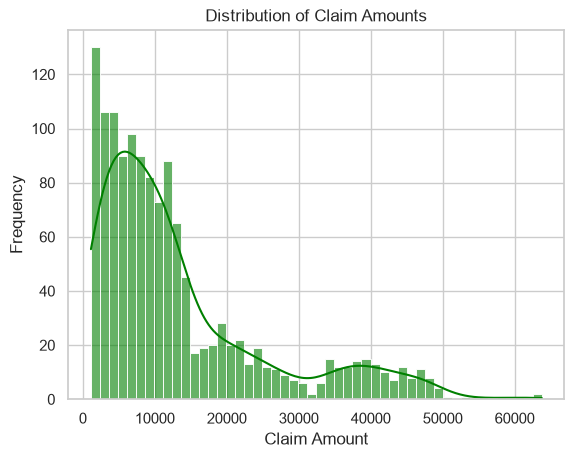

In [8]:
sns.histplot(data = df, x = "claim", bins = 50, kde = True, color = "green", alpha = 0.6)
plt.title("Distribution of Claim Amounts")
plt.xlabel("Claim Amount")
plt.ylabel("Frequency")
plt.show()


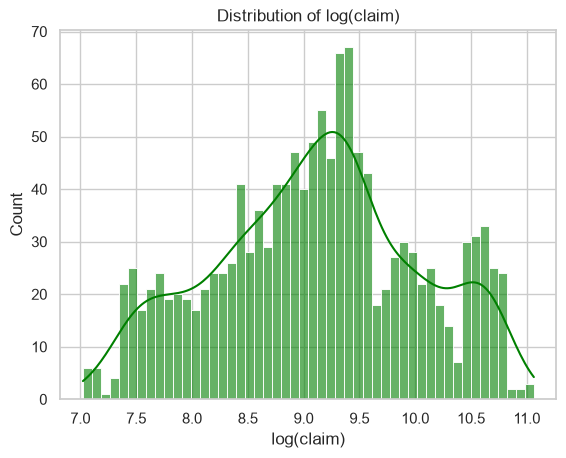

In [15]:


sns.histplot(x=np.log(df["claim"]), bins=50, kde=True, color="green", alpha=0.6)
plt.title("Distribution of log(claim)")
plt.xlabel("log(claim)")
plt.ylabel("Count")
plt.show()



## Insight
Claim amounts are right skewed and unimodal; most claims roughly fall betwen $8,000-$13,000. The long tail of large claims pulls the mean above the median as it can be viusally seen in the first plot, where the log transformation allows for a more symmetrics distribution.

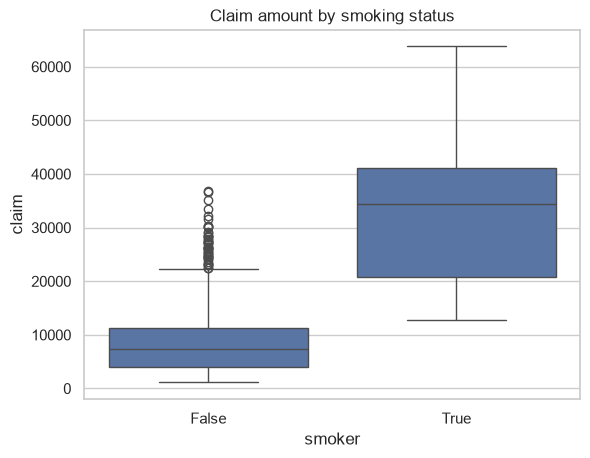

In [16]:
sns.boxplot(data=df, x="smoker", y="claim")
plt.title("Claim amount by smoking status")
plt.show()
